In [1]:
#Importing the necessary libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder,RobustScaler
import warnings
warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
%matplotlib inline

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV



In [2]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [3]:
data=pd.read_csv("bank-additional-full.xls.csv")

In [4]:
data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


# BASIC CHECKS

In [5]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [6]:
data.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [7]:
data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

No Missing data values

In [9]:
data.rename(columns={'y': 'deposit'}, inplace=True)

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

# Exploratory Data Analysis

In [11]:
# Numerical columns
numerical_cols = data.select_dtypes(include=['int64', 'float64']).columns

In [12]:
numerical_cols

Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')

In [13]:
# Categorical columns
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()

In [14]:
categorical_cols

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'poutcome',
 'deposit']

# Univarient data analysis

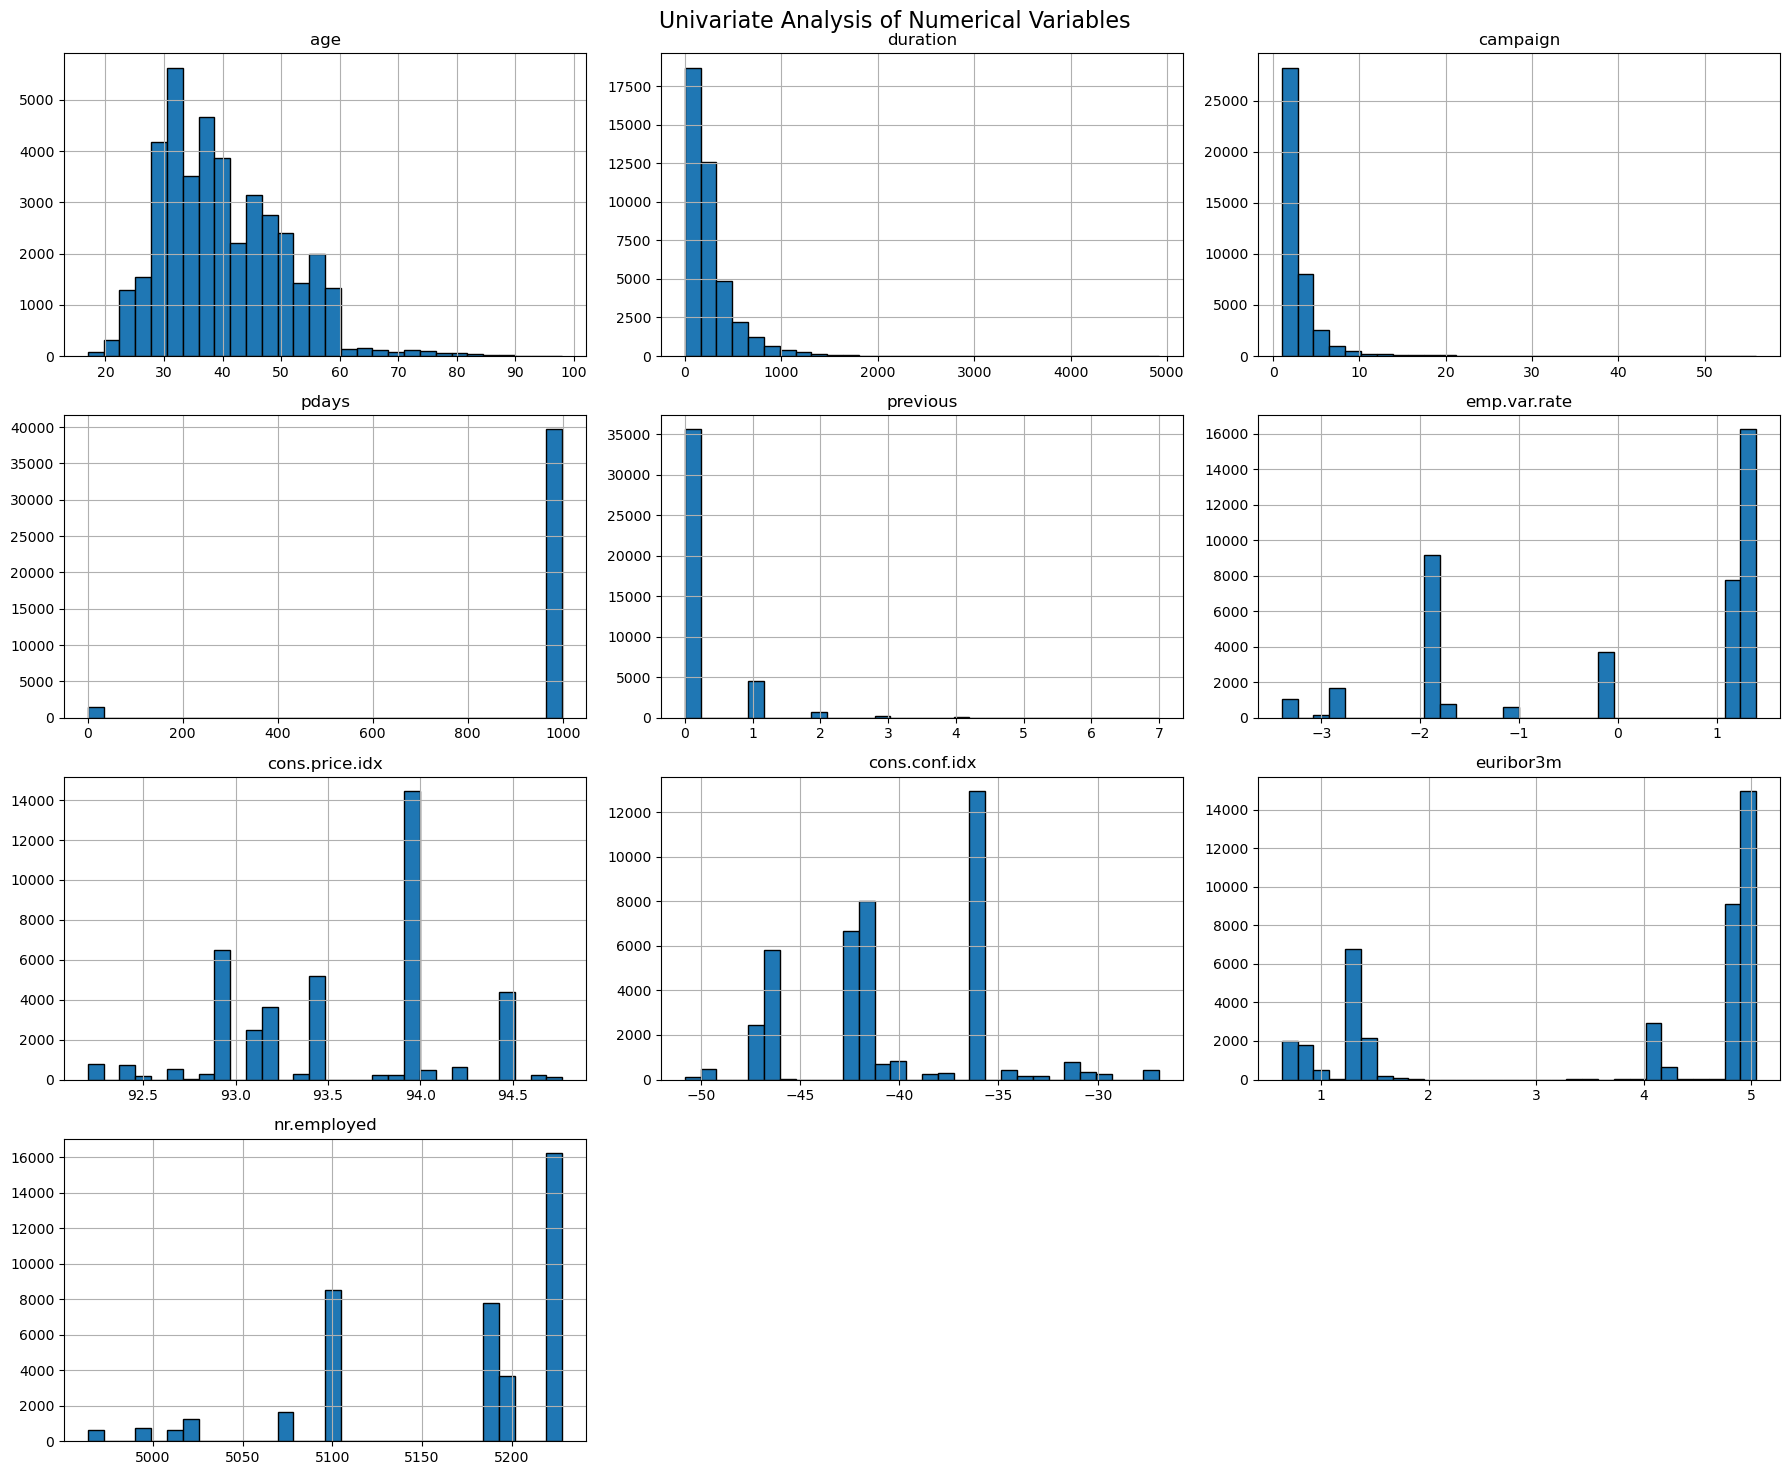

In [15]:

data[numerical_cols].hist(
    figsize=(18, 15),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Univariate Analysis of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

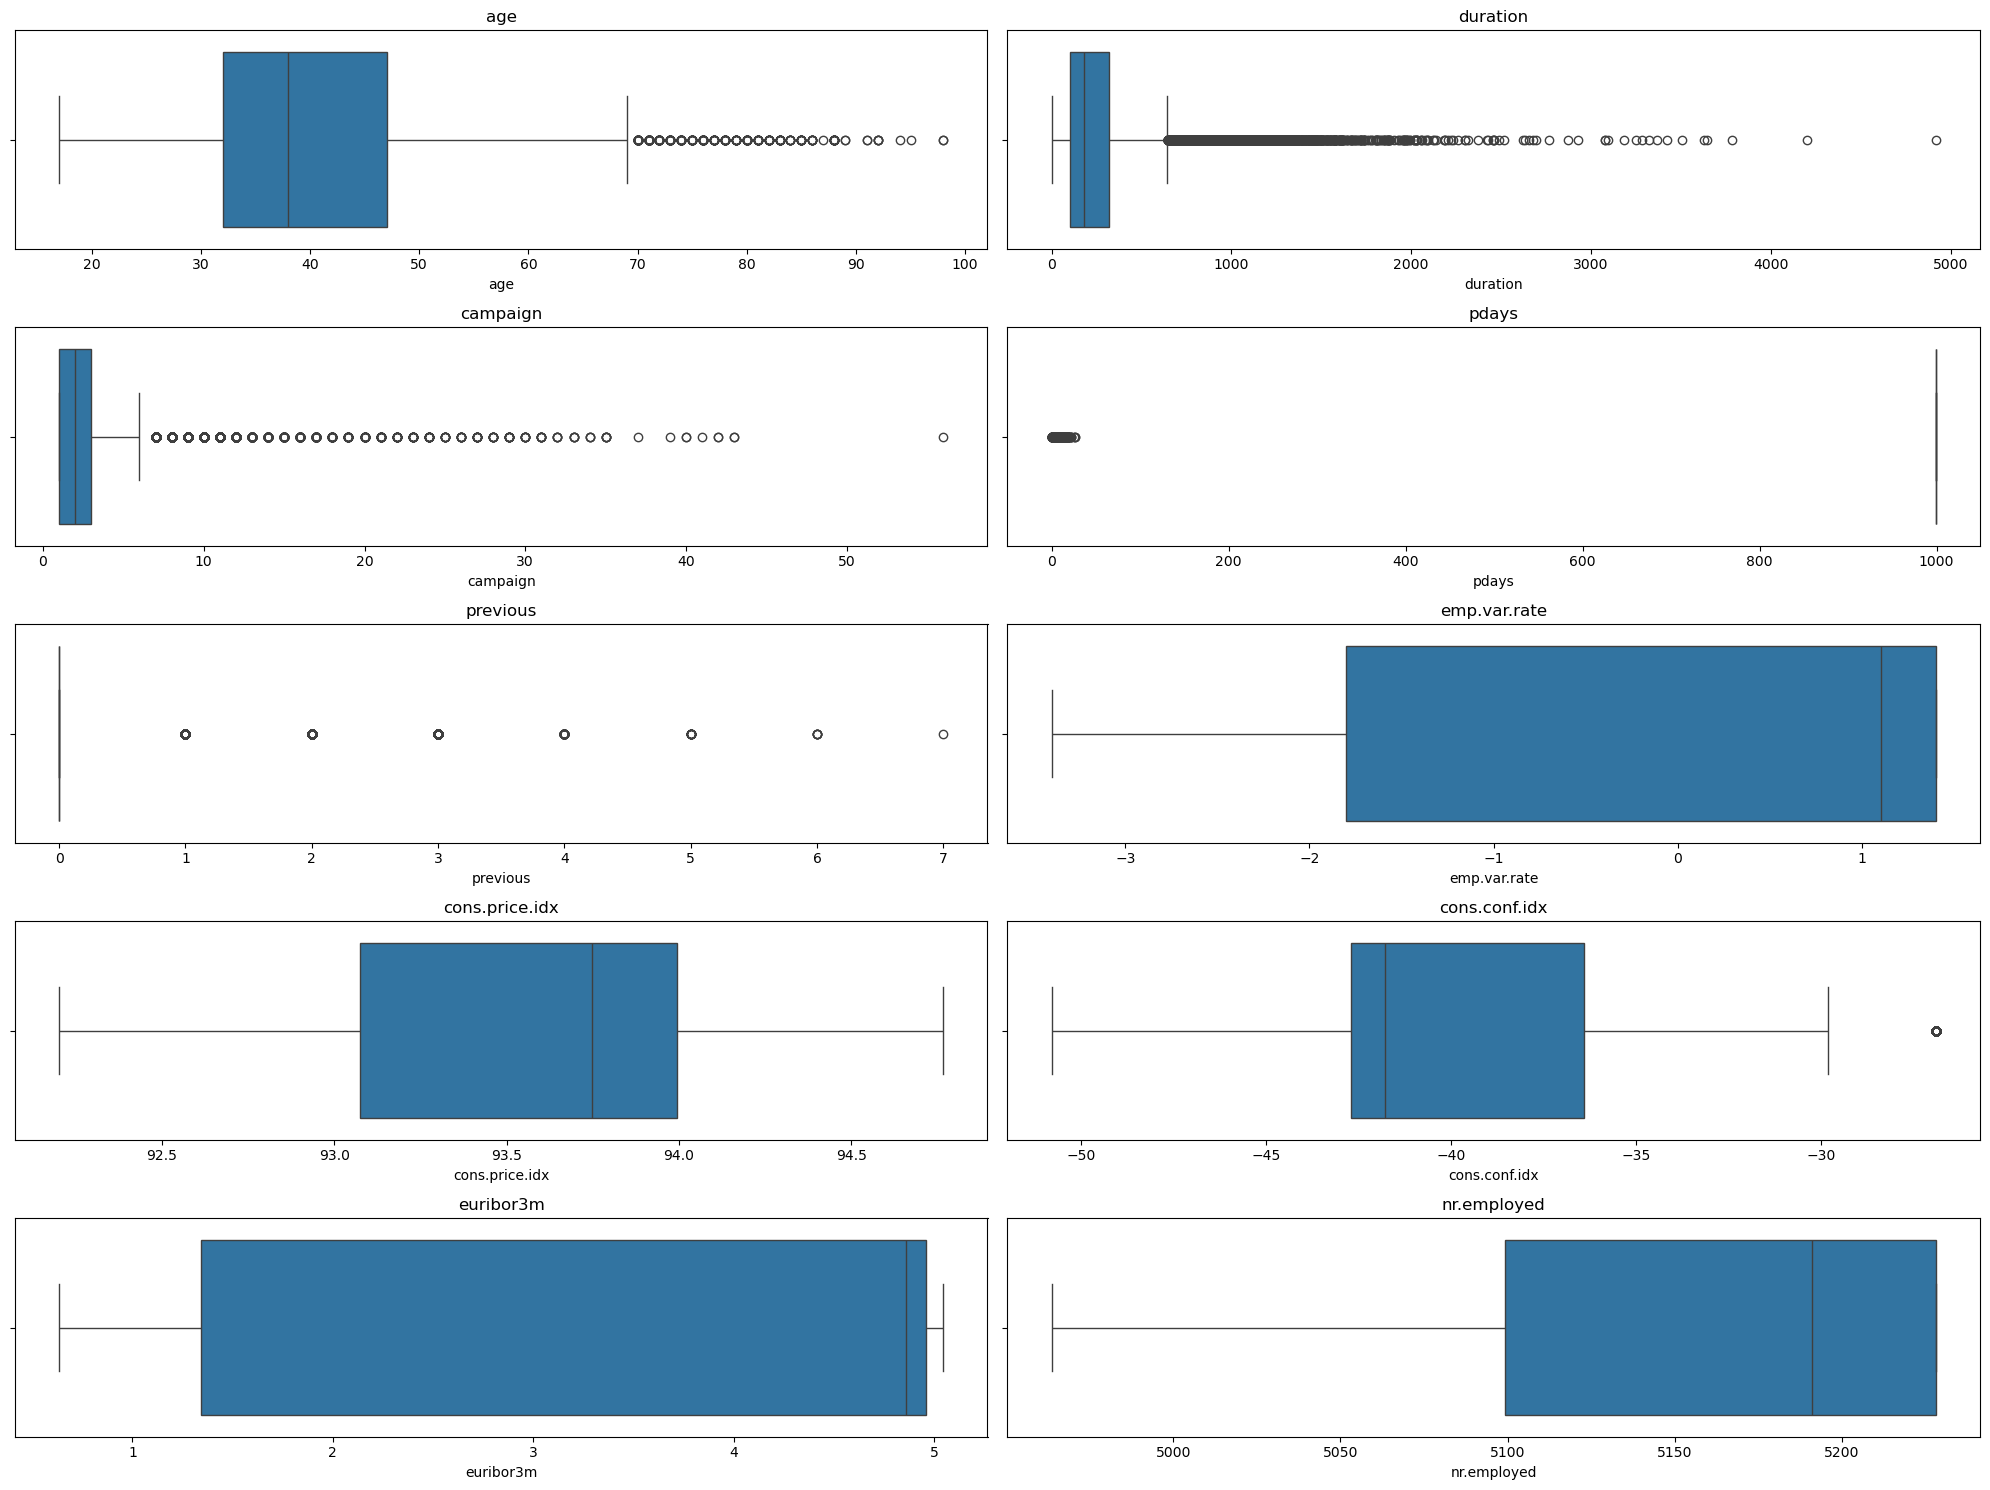

In [16]:
### -Checking the outliers using boxplot

plt.figure(figsize=(20, 15))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(5, 2, i)
    sns.boxplot(x=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [17]:
for col in categorical_cols:
    print(f"\n Frequency distribution of {col}")
    #print(f"\n ")
    print(data[col].value_counts())


 Frequency distribution of job
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

 Frequency distribution of marital
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

 Frequency distribution of education
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

 Frequency distribution of default
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

 Frequency distribution of housing
housing
yes        21576
no         18622
unknown      99

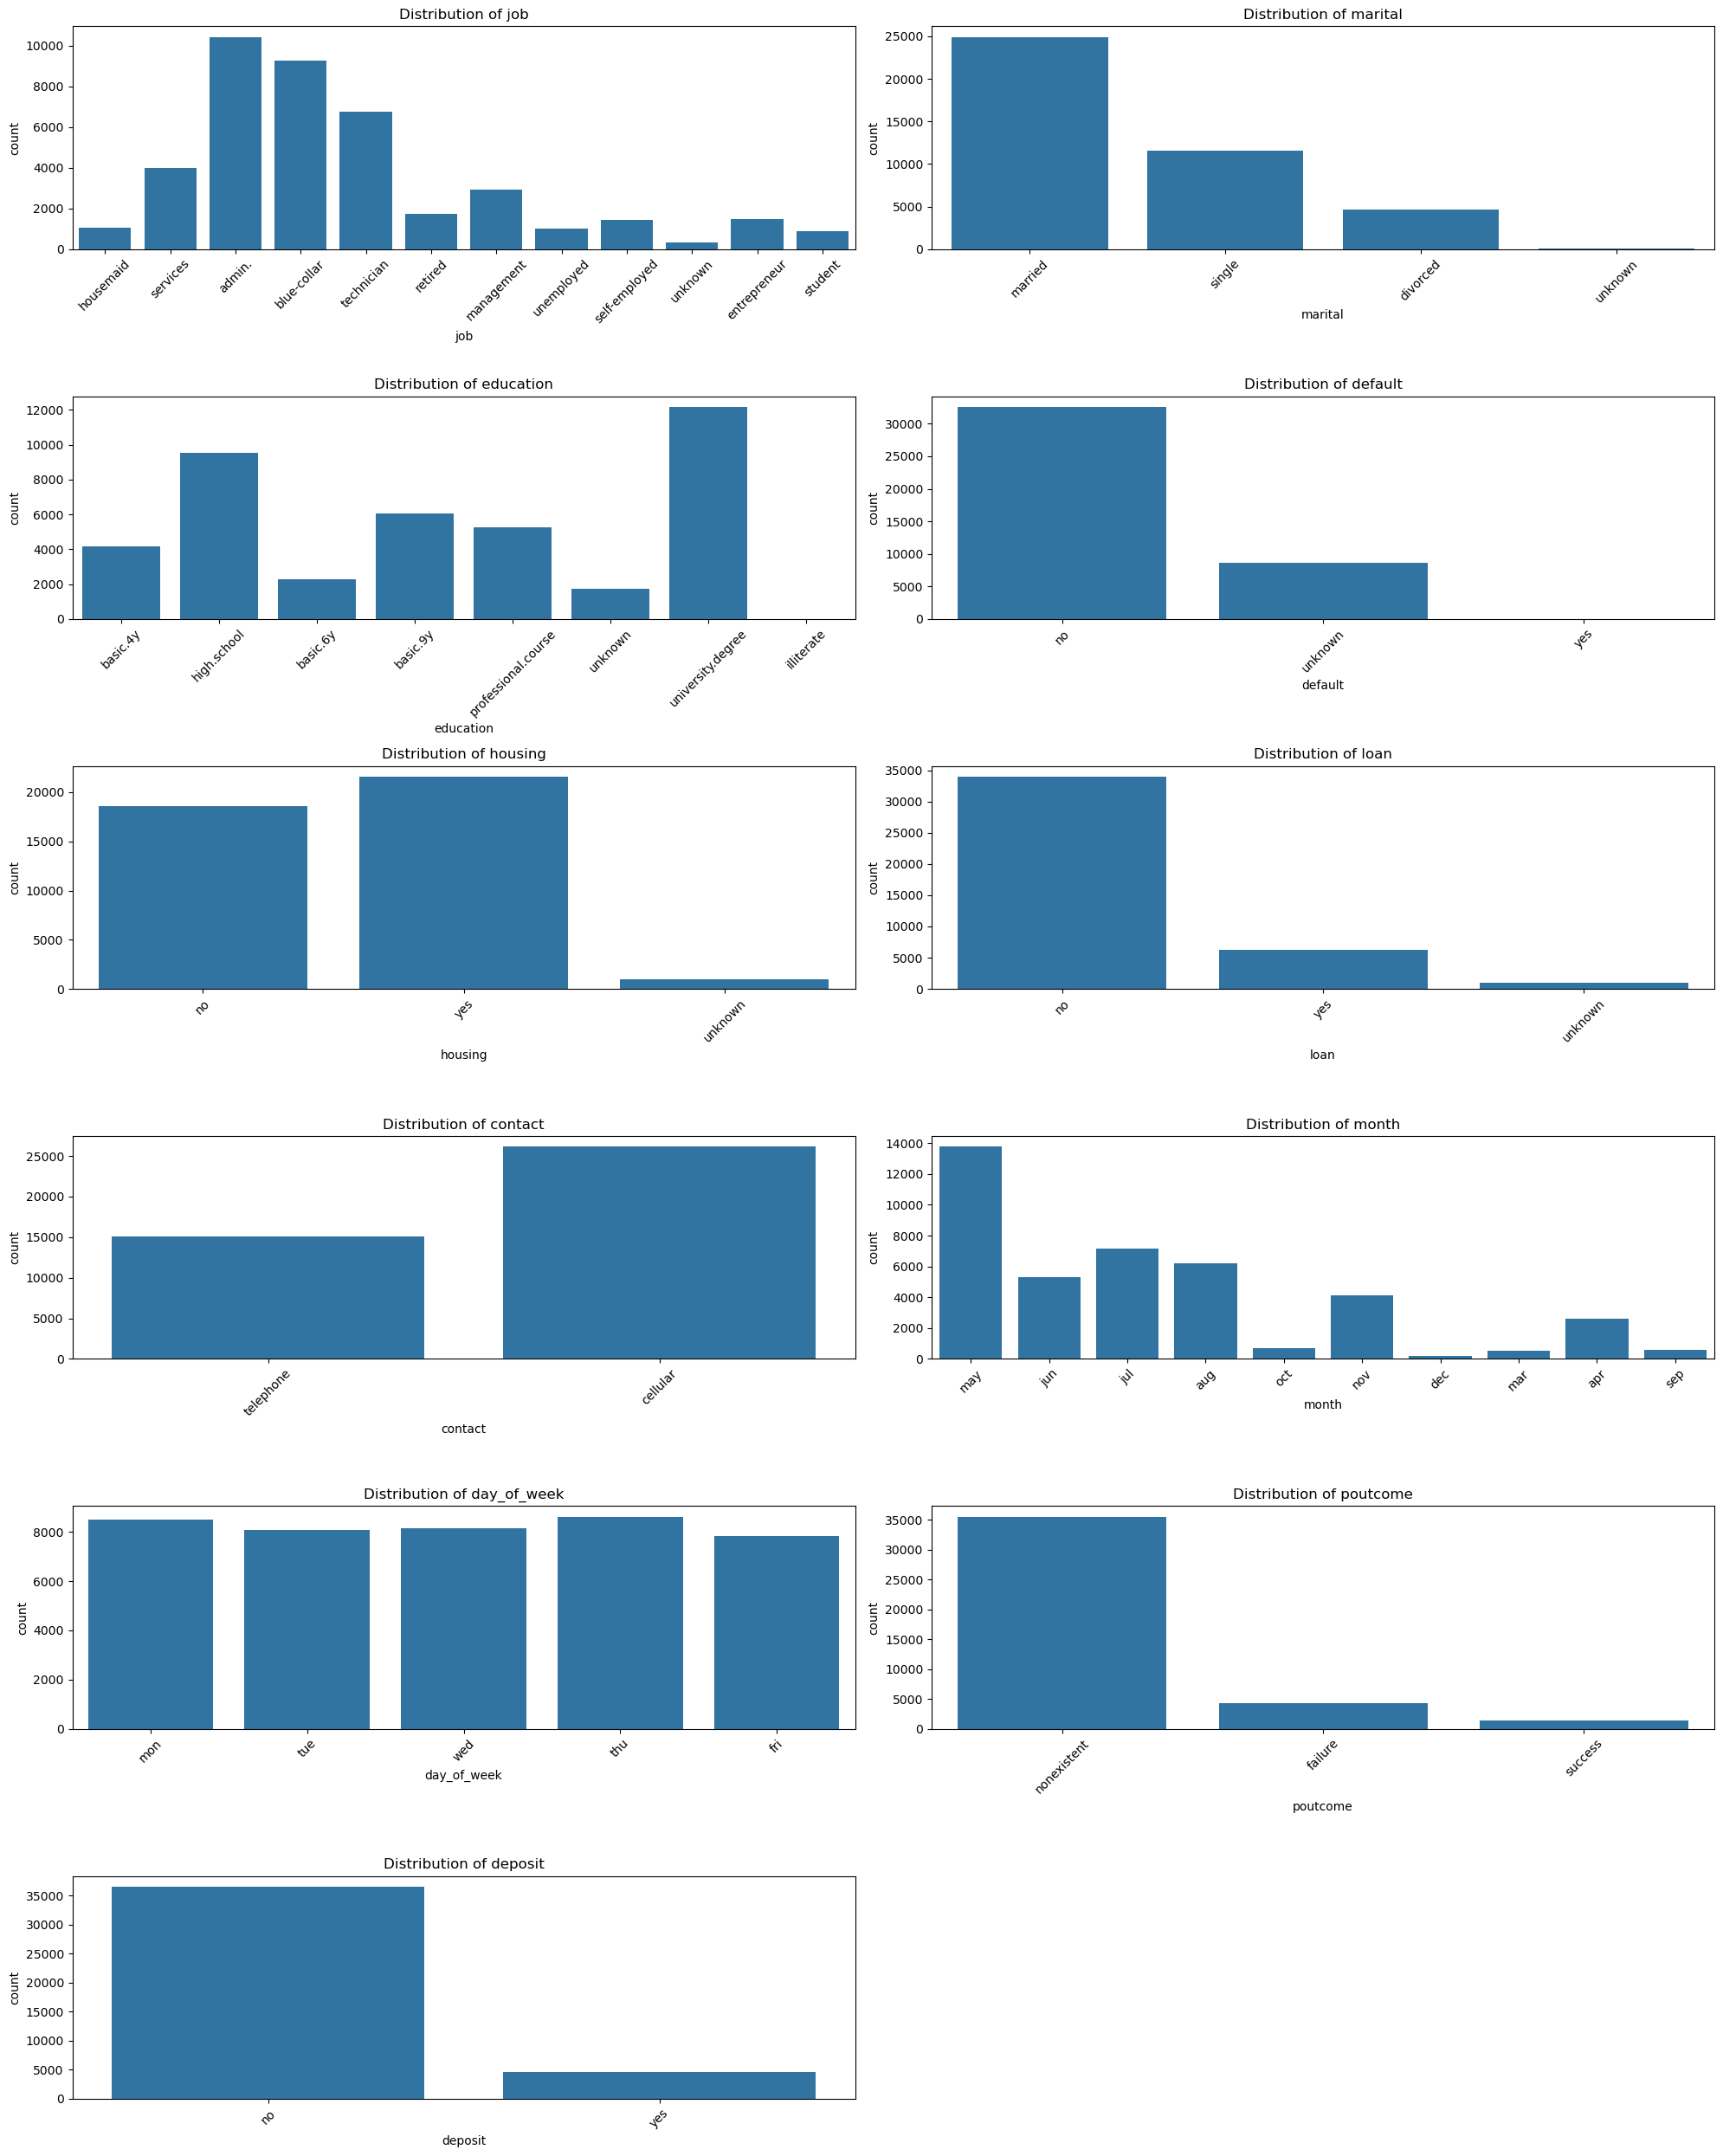

In [18]:
# Graphical Representation 

plt.figure(figsize=(20, 25))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(6, 2, i)
    sns.countplot(data=data, x=col)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [19]:
print(data['deposit'].value_counts())

print("\nTarget percentages:")
print((data['deposit'].value_counts(normalize=True) * 100).round(2))

deposit
no     36548
yes     4640
Name: count, dtype: int64

Target percentages:
deposit
no     88.73
yes    11.27
Name: proportion, dtype: float64


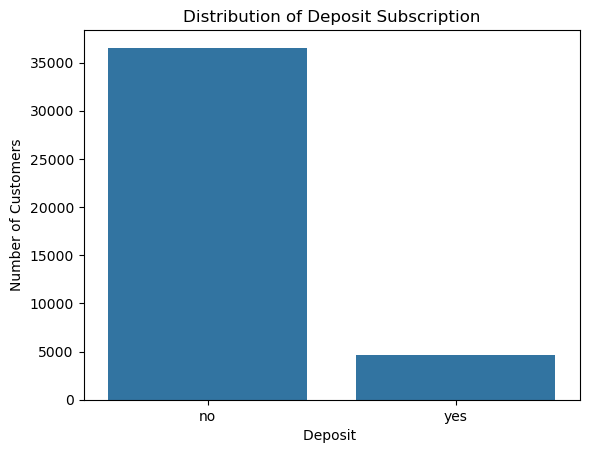

In [20]:
sns.countplot(data=data, x='deposit')
plt.title("Distribution of Deposit Subscription")
plt.xlabel("Deposit ")
plt.ylabel("Number of Customers")
plt.show()

# Bivariate Data Analysis

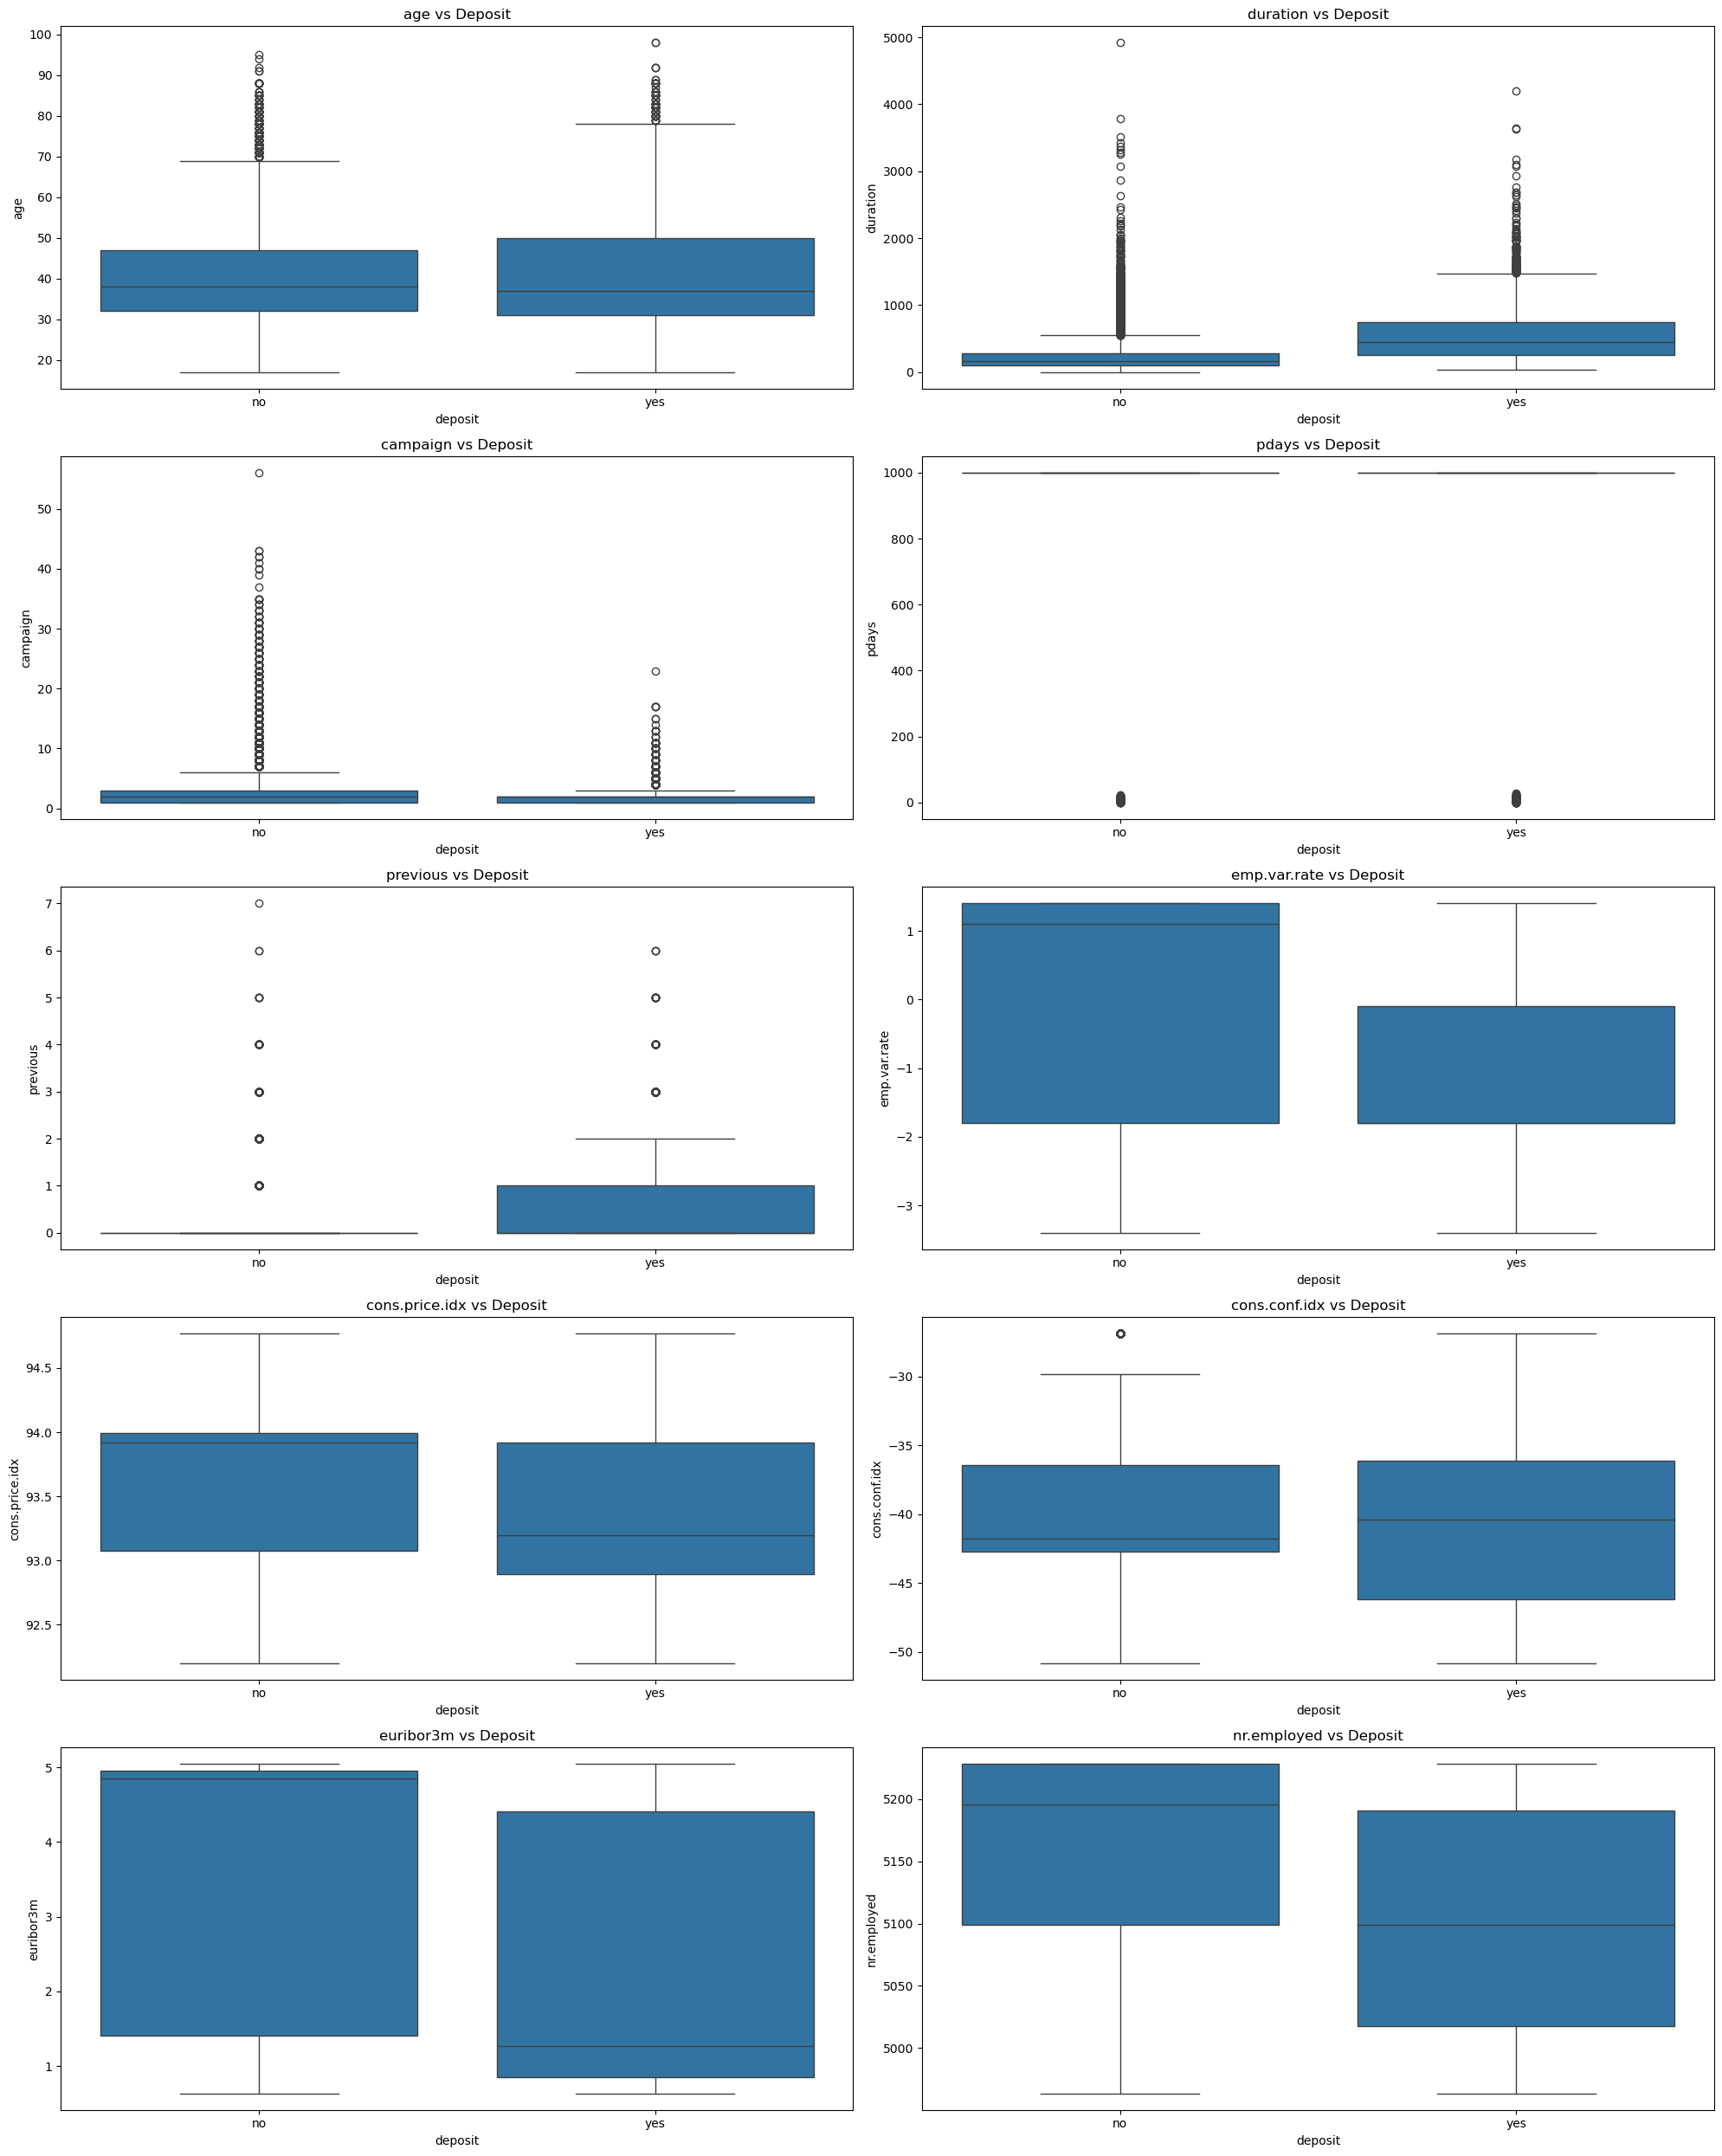

In [21]:
# Boxplots for Numerical features versus the target
plt.figure(figsize=(20, 25))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(5, 2, i)
    sns.boxplot(data=data, x='deposit', y=col)
    plt.title(f'{col} vs Deposit')

plt.tight_layout()
plt.show()

In [22]:
data.groupby('deposit')[numerical_cols].agg(
    ['mean', 'median', 'std']
).T

deposit                         no          yes
age            mean      39.911185    40.913147
               median    38.000000    37.000000
               std        9.898132    13.837476
duration       mean     220.844807   553.191164
               median   163.500000   449.000000
               std      207.096293   401.171871
campaign       mean       2.633085     2.051724
               median     2.000000     2.000000
               std        2.873438     1.666245
pdays          mean     984.113878   792.035560
               median   999.000000   999.000000
               std      120.656868   403.407181
previous       mean       0.132374     0.492672
               median     0.000000     0.000000
               std        0.409199     0.860344
emp.var.rate   mean       0.248875    -1.233448
               median     1.100000    -1.800000
               std        1.482932     1.623626
cons.price.idx mean      93.603757    93.354386
               median    93.918000    93.200000
               std        0.558993     0.676644
cons.conf.idx  mean     -40.593097   -39.789784
               median   -41.800000   -40.400000
               std        4.391155     6.139668
euribor3m      mean       3.811491     2.123135
               median     4.857000     1.266000
               std        1.638187     1.742598
nr.employed    mean    5176.166600  5095.115991
               median  5195.800000  5099.100000
               std       64.571979    87.572641

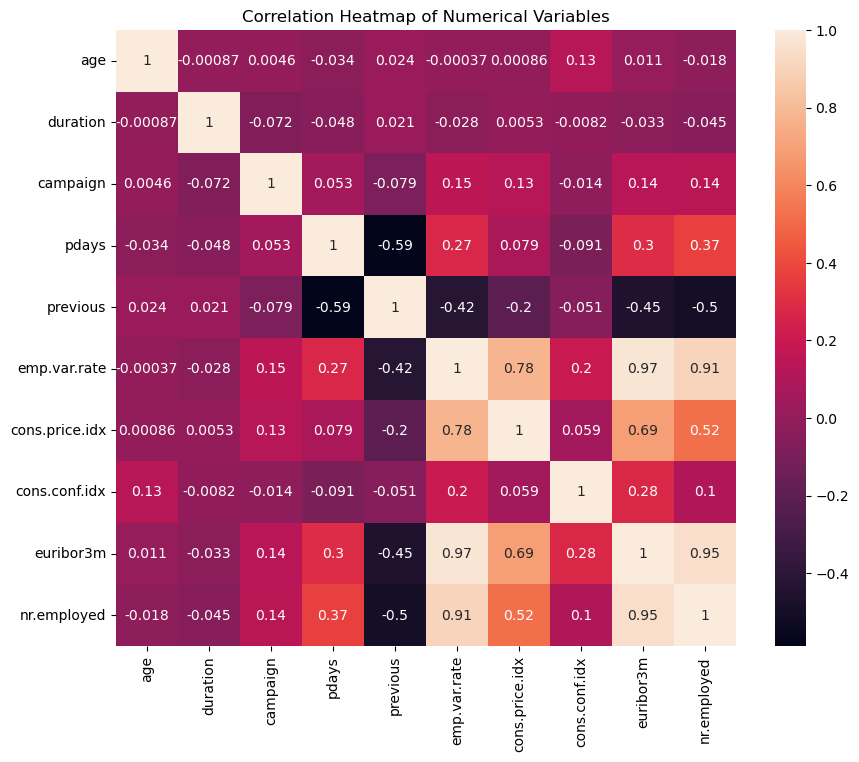

In [23]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    data[numerical_cols].corr(),
    annot=True,
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()


In [24]:
# Heatmap shows the correlation between following features :
#      Feature 1      Feature 2     Correlation
# 1)  emp.var.rate    euribor3m     0.972245
# 2)  emp.var.rate  nr.employed     0.906970
# 3)  euribor3m     nr.employed     0.945154    


In [25]:
data_logistic = data.drop(
    columns=['emp.var.rate', 'nr.employed']
)

print(data_logistic.shape)

(41188, 19)


In [26]:
data_logistic

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons.price.idx,cons.conf.idx,euribor3m,deposit
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,93.994,-36.4,4.857,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,93.994,-36.4,4.857,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,93.994,-36.4,4.857,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,93.994,-36.4,4.857,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,93.994,-36.4,4.857,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,94.767,-50.8,1.028,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,94.767,-50.8,1.028,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,94.767,-50.8,1.028,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,94.767,-50.8,1.028,yes


In [27]:
for col in categorical_cols:
    if col != 'deposit':
        print(f"\n{col} vs Deposit")
        print(pd.crosstab(data[col], data['deposit']))


job vs Deposit
deposit          no   yes
job                      
admin.         9070  1352
blue-collar    8616   638
entrepreneur   1332   124
housemaid       954   106
management     2596   328
retired        1286   434
self-employed  1272   149
services       3646   323
student         600   275
technician     6013   730
unemployed      870   144
unknown         293    37

marital vs Deposit
deposit      no   yes
marital              
divorced   4136   476
married   22396  2532
single     9948  1620
unknown      68    12

education vs Deposit
deposit                 no   yes
education                       
basic.4y              3748   428
basic.6y              2104   188
basic.9y              5572   473
high.school           8484  1031
illiterate              14     4
professional.course   4648   595
university.degree    10498  1670
unknown               1480   251

default vs Deposit
deposit     no   yes
default             
no       28391  4197
unknown   8154   443
yes         

In [28]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 12


In [29]:
print("pdays value counts:")
print(data['pdays'].value_counts().head(10))

print("\nUnknown categories:")
for col in categorical_cols:
    if col != 'deposit':
        print(col, (data[col] == 'unknown').sum())

pdays value counts:
pdays
999    39673
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
Name: count, dtype: int64

Unknown categories:
job 330
marital 80
education 1731
default 8597
housing 990
loan 990
contact 0
month 0
day_of_week 0
poutcome 0


# DATA PREPROCESSING AND FEATURE ENGINEERING

In [30]:
# Handling the missing values

data_logistic.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
deposit           0
dtype: int64

In [31]:
# Count outliers in each numerical column

import pandas as pd

numerical_cols = data_logistic.select_dtypes(include=['int64', 'float64']).columns

outlier_summary = []

for col in numerical_cols:
    Q1 = data_logistic[col].quantile(0.25)
    Q3 = data_logistic[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data_logistic[(data_logistic[col] < lower_limit) | (data_logistic[col] > upper_limit)]

    outlier_summary.append({
        'Column': col,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
    })

outlier_summary = pd.DataFrame(outlier_summary)

print(outlier_summary)

           Column  Lower Limit  Upper Limit
0             age       9.5000      69.5000
1        duration    -223.5000     644.5000
2        campaign      -2.0000       6.0000
3           pdays     999.0000     999.0000
4        previous       0.0000       0.0000
5  cons.price.idx      91.6965      95.3725
6   cons.conf.idx     -52.1500     -26.9500
7       euribor3m      -4.0815      10.3865


In [32]:
# Removing Outliers using IQR

numerical_cols = data_logistic.select_dtypes(include=['int64', 'float64']).columns

data_clean = data_logistic.copy()

for col in numerical_cols:
    Q1 = data_clean[col].quantile(0.25)
    Q3 = data_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    data_clean = data_clean[
        (data_clean[col] >= lower_limit) &
        (data_clean[col] <= upper_limit)
    ]

print("Original dataset shape:", data_logistic.shape)
print("Dataset shape after removing outliers:", data_clean.shape)
print("Rows removed:", len(data_logistic) - len(data_clean))

Original dataset shape: (41188, 19)
Dataset shape after removing outliers: (23106, 19)
Rows removed: 18082


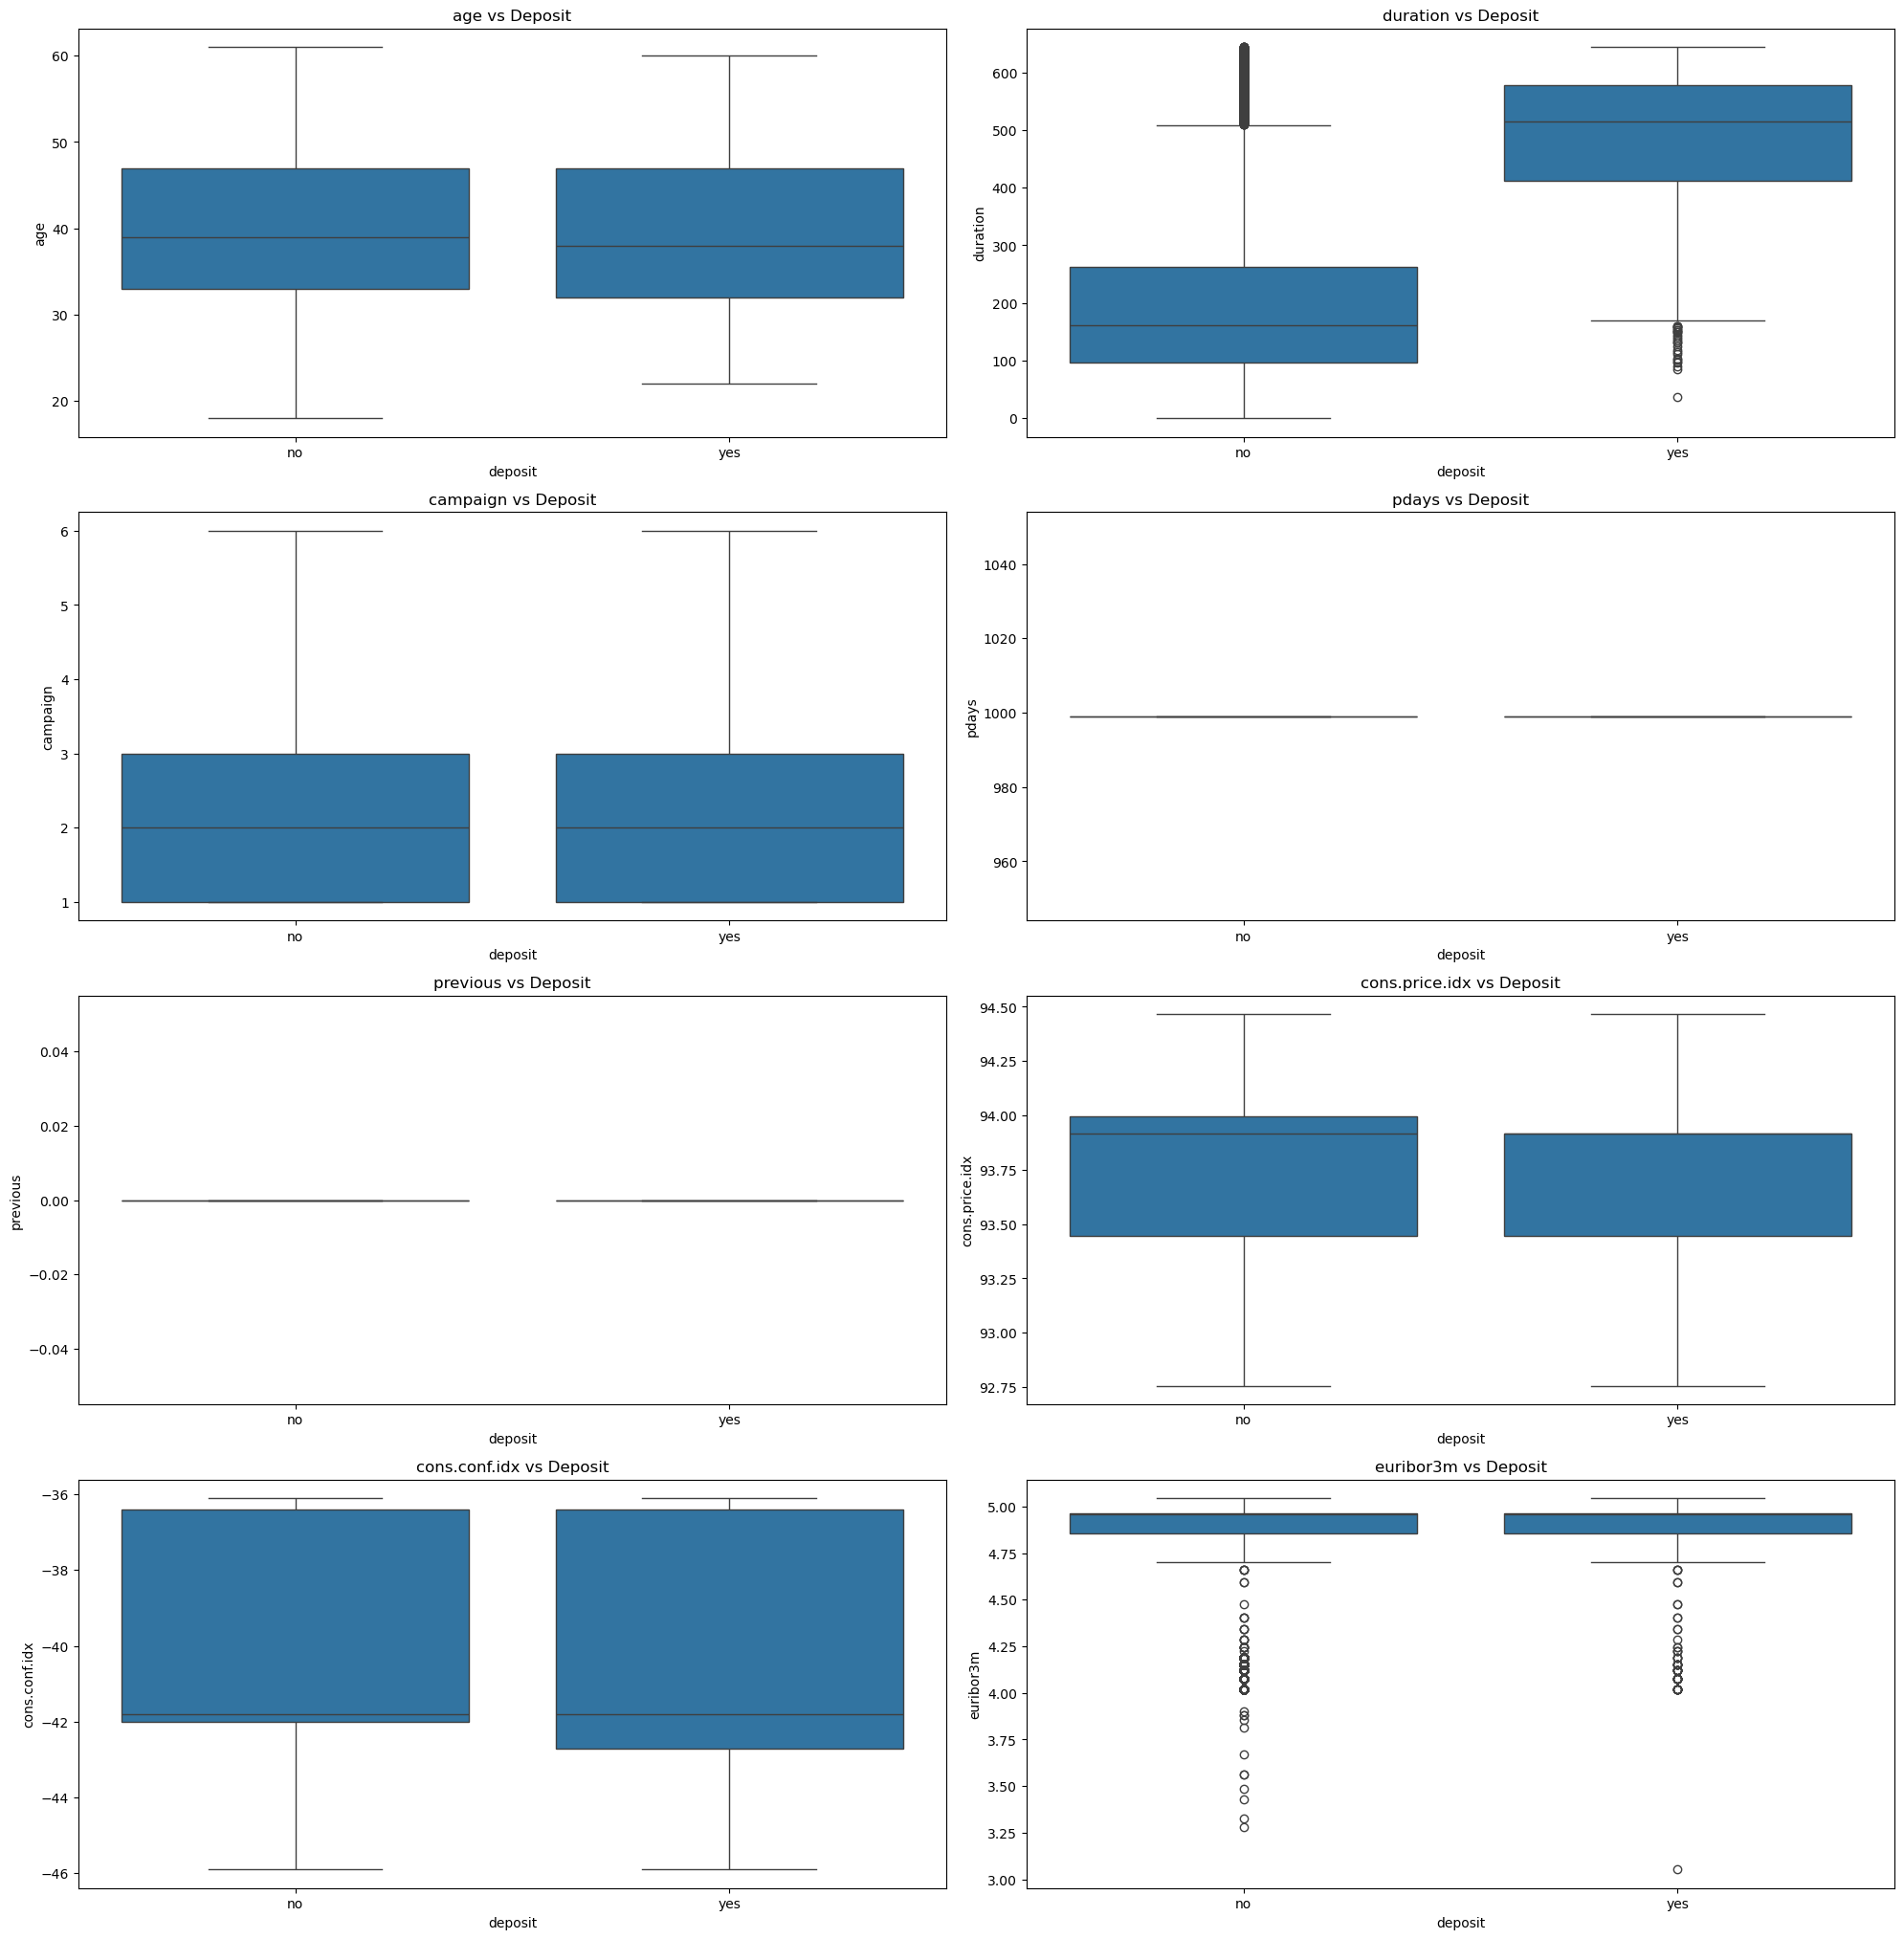

In [33]:
plt.figure(figsize=(20, 25))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(5, 2, i)
    sns.boxplot(data=data_clean, x='deposit', y=col)
    plt.title(f'{col} vs Deposit')

plt.tight_layout()
plt.show()

In [34]:
for col in numerical_cols:
    
    skew_value = data[col].skew()
    
    print("Column Name :", col)
    print("Skew Value  :", skew_value)
    
    # Check skew type
    if skew_value > 0:
        print(col, "is Positively Skewed")
        
    elif skew_value < 0:
        print(col, "is Negatively Skewed")
        
    else:
        print(col, "has No Skew")
    
    print("---------------------------")

Column Name : age
Skew Value  : 0.7846968157646645
age is Positively Skewed
---------------------------
Column Name : duration
Skew Value  : 3.2631412552628314
duration is Positively Skewed
---------------------------
Column Name : campaign
Skew Value  : 4.762506697067007
campaign is Positively Skewed
---------------------------
Column Name : pdays
Skew Value  : -4.922189916418163
pdays is Negatively Skewed
---------------------------
Column Name : previous
Skew Value  : 3.832042242861185
previous is Positively Skewed
---------------------------
Column Name : cons.price.idx
Skew Value  : -0.23088765135788
cons.price.idx is Negatively Skewed
---------------------------
Column Name : cons.conf.idx
Skew Value  : 0.3031798587481924
cons.conf.idx is Positively Skewed
---------------------------
Column Name : euribor3m
Skew Value  : -0.7091879563778315
euribor3m is Negatively Skewed
---------------------------


<Axes: >

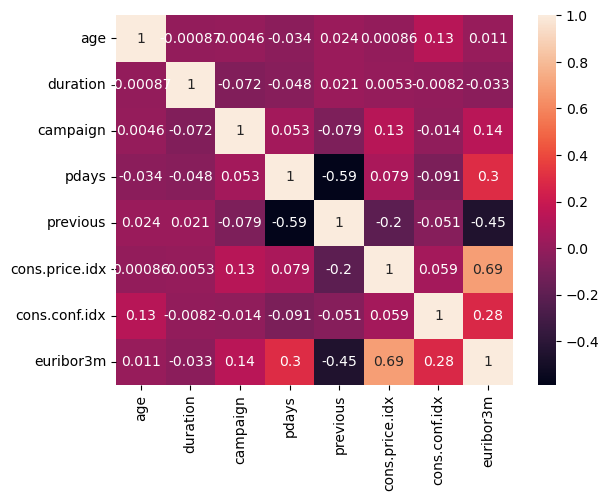

In [35]:
# Finding the relation between the input features

sns.heatmap(data_logistic.select_dtypes(include=['int', 'float']).corr(),annot=True)

In [36]:
data_logistic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  cons.price.idx  41188 non-null  float64
 16  cons.conf.idx   41188 non-null  float64
 17  euribor3m       41188 non-null 

In [37]:
data_logistic

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons.price.idx,cons.conf.idx,euribor3m,deposit
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,93.994,-36.4,4.857,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,93.994,-36.4,4.857,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,93.994,-36.4,4.857,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,93.994,-36.4,4.857,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,93.994,-36.4,4.857,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,94.767,-50.8,1.028,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,94.767,-50.8,1.028,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,94.767,-50.8,1.028,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,94.767,-50.8,1.028,yes


In [38]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [39]:
data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,deposit
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [40]:
data_logistic.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'cons.price.idx', 'cons.conf.idx', 'euribor3m',
       'deposit'],
      dtype='object')

In [41]:
data.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'deposit'],
      dtype='object')

In [42]:
OHE_col=['job','marital','contact','month','poutcome']
ss_col=["age","duration","campaign","pdays","previous"]
robust_col=["cons.price.idx","cons.conf.idx","euribor3m"]
OE_col=['housing', 'loan', 'default','education']


In [43]:
preprocessor = ColumnTransformer([('OHE',OneHotEncoder(),OHE_col),
                                  ('SS',StandardScaler(),ss_col),
                                  ('Robust',RobustScaler(),robust_col),
                                  ('Order',OrdinalEncoder(), OE_col),                                 
                                ])

In [44]:
preprocessor

,transformers,"[('OHE', ...), ('SS', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,categories,'auto'
,drop,None
,sparse_output,True


In [45]:
#with open('Model1.pkl','wb') as f:
 #   pickle.dump(preprocessor,f)

In [46]:
#with open('Processed_data.pkl','wb') as f:
#    pickle.dump(data,f)

# Model Creation

In [47]:
# Seperating Feature and target columns

In [48]:
x = data.drop('deposit',axis=1)
y = data['deposit'].map({"no":0,"yes":1})

In [49]:
# Spliting the data into train and test

from sklearn.model_selection import train_test_split
x_train_raw,x_test_raw,y_train,y_test = train_test_split(x,y,test_size = 0.2, random_state = 42, stratify = y)

In [51]:
# Transform the training data using the preprocessor object 

x_train=preprocessor.fit_transform(x_train_raw)
x_test=preprocessor.transform(x_test_raw)

In [52]:
x_train.shape

(32950, 43)

In [53]:
y_train.value_counts()

deposit
0    29238
1     3712
Name: count, dtype: int64

In [54]:
from collections import Counter
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
x_smote, y_smote = smote.fit_resample(x_train, y_train)

print("SMOTE class distribution:", Counter(y_smote))

#x_smote,y_smote = SMOTE().fit_resample(x_train,y_train)
#print("SMOTE class distribution:", Counter(y_smote))

SMOTE class distribution: Counter({0: 29238, 1: 29238})


# LOGISTIC REGRESSION MODEL

In [55]:
## Model creation

from sklearn.linear_model import LogisticRegression
clf=LogisticRegression(random_state=42)
clf.fit(x_smote,y_smote)  ## training data

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [56]:
# Getting predictions from model for test data
y_test_pred=clf.predict(x_test)

# Getting predictions from model for train data
y_train_pred=clf.predict(x_smote)

In [57]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Testing Accuracy",accuracy_score(y_test,y_test_pred))
print("Training Accuracy",accuracy_score(y_smote,y_train_pred))
print(classification_report(y_test,y_test_pred))

print("F1 Score",f1_score(y_test, y_test_pred, zero_division=0))


Testing Accuracy 0.8652585579024035
Training Accuracy 0.8754189753061085
              precision    recall  f1-score   support

           0       0.98      0.86      0.92      7310
           1       0.45      0.90      0.60       928

    accuracy                           0.87      8238
   macro avg       0.72      0.88      0.76      8238
weighted avg       0.92      0.87      0.88      8238

F1 Score 0.5998558038932948


In [58]:
y_test.value_counts()

deposit
0    7310
1     928
Name: count, dtype: int64

# TREE MODEL

In [59]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import GridSearchCV

from xgboost import XGBClassifier


from sklearn.metrics import accuracy_score, f1_score

from sklearn.ensemble import RandomForestClassifier

In [60]:
# =========================================================
# TRAIN TEST SCORE FUNCTION
# =========================================================

def train_score(model,x_train,y_train):

    y_train_pred=model.predict(x_train)
    train_accuracy=accuracy_score(y_train,y_train_pred)
    print("Train Accuracy :",train_accuracy)
    

def test_score(model,x_test,y_test):

    y_test_pred=model.predict(x_test)
    test_accuracy=accuracy_score(y_test,y_test_pred)
    print("Test Accuracy :",test_accuracy)
    print("\nClassification Report\n")

    print(classification_report(
        y_test,
        y_test_pred
    ))

# =========================================================

In [61]:
# =========================================================
# DECISION TREE MODEL
# =========================================================

def build_decision_tree(x_train,y_train):

    model=DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        random_state=42
    )

    model.fit(x_train,y_train)

    return model


# =========================================================
# HYPERPARAMETER TUNING
# =========================================================

def tuned_decision_tree(x_train,y_train):

    params={
        'criterion':['gini','entropy'],
        'max_depth':[3,5,10]
    }

    grid_search=GridSearchCV(
        estimator=DecisionTreeClassifier(
        random_state=42),
        param_grid=params,
        cv=5,
        scoring='accuracy'
    )

    grid_search.fit(x_train,y_train)

    print("Best Parameters :",
          grid_search.best_params_)

    return grid_search.best_estimator_

In [62]:
# =========================================================
# RANDOM FOREST MODEL
# =========================================================

def build_random_forest_model(x_train,y_train):

    model=RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )

    model.fit(x_train,y_train)

    return model

In [63]:
# =========================================================
# BAGGING MODEL
# =========================================================

def build_bagging_model(x_train,y_train):

    model=BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        random_state=42
    )

    model.fit(x_train,y_train)

    return model

In [64]:
# =========================================================
# GRADIENT BOOSTING MODEL
# =========================================================

def build_gradient_boosting_model(x_train,y_train):

    model=GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )

    model.fit(x_train,y_train)

    return model

In [65]:
# =========================================================
# XGBOOST MODEL
# =========================================================

def build_xgboost_model(x_train,y_train):

    model=XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )

    model.fit(x_train,y_train)

    return model

## Callling the Functions

In [66]:
# =========================================================
# DECISION TREE
# =========================================================

decision_tree_model=build_decision_tree(
    x_smote,
    y_smote
)

print("\nDecision Tree Train Result")

train_score(
    decision_tree_model,
    x_smote,
    y_smote
)

print("\nDecision Tree Test Result")

test_score(
    decision_tree_model,
    x_test,
    y_test
)

print("F1 Score",f1_score(y_test, y_test_pred, zero_division=0))



Decision Tree Train Result
Train Accuracy : 0.886568848758465

Decision Tree Test Result
Test Accuracy : 0.8606457878125758

Classification Report

              precision    recall  f1-score   support

           0       0.99      0.86      0.92      7310
           1       0.44      0.90      0.59       928

    accuracy                           0.86      8238
   macro avg       0.71      0.88      0.75      8238
weighted avg       0.92      0.86      0.88      8238

F1 Score 0.5998558038932948


In [67]:
# =========================================================
# TUNED DECISION TREE
# =========================================================

tuned_dt_model=tuned_decision_tree(
    x_smote,
    y_smote
)

print("\nTuned DT Train Result")

train_score(
    tuned_dt_model,
    x_smote,
    y_smote
)

print("\nTuned DT Test Result")

test_score(
    tuned_dt_model,
    x_test,
    y_test
)


print("F1 Score",f1_score(y_test, y_test_pred, zero_division=0))

Best Parameters : {'criterion': 'gini', 'max_depth': 10}

Tuned DT Train Result
Train Accuracy : 0.9325706272658869

Tuned DT Test Result
Test Accuracy : 0.8766690944403982

Classification Report

              precision    recall  f1-score   support

           0       0.98      0.88      0.93      7310
           1       0.47      0.84      0.60       928

    accuracy                           0.88      8238
   macro avg       0.72      0.86      0.77      8238
weighted avg       0.92      0.88      0.89      8238

F1 Score 0.5998558038932948


In [68]:
# =========================================================
# RANDOM FOREST MODEL
# =========================================================

random_forest_model=build_random_forest_model(
    x_smote,
    y_smote
)

print("\n")
print("="*60)
print("RANDOM FOREST MODEL")
print("="*60)

train_score(
    random_forest_model,
    x_smote,
    y_smote
)

test_score(
    random_forest_model,
    x_test,
    y_test
)
print("F1 Score",f1_score(y_test, y_test_pred, zero_division=0))



RANDOM FOREST MODEL
Train Accuracy : 0.891955674122717
Test Accuracy : 0.8434085943190095

Classification Report

              precision    recall  f1-score   support

           0       0.98      0.84      0.90      7310
           1       0.41      0.89      0.56       928

    accuracy                           0.84      8238
   macro avg       0.70      0.86      0.73      8238
weighted avg       0.92      0.84      0.87      8238

F1 Score 0.5998558038932948


In [69]:
# =========================================================
# BAGGING MODEL
# =========================================================

bagging_model=build_bagging_model(
    x_smote,
    y_smote
)

print("\nBagging Train Result")

train_score(
    bagging_model,
    x_smote,
    y_smote
)

print("\nBagging Test Result")

test_score(
    bagging_model,
    x_test,
    y_test
)


print("F1 Score",f1_score(y_test, y_test_pred, zero_division=0))



Bagging Train Result
Train Accuracy : 1.0

Bagging Test Result
Test Accuracy : 0.9095654285020636

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.94      0.95      7310
           1       0.58      0.70      0.64       928

    accuracy                           0.91      8238
   macro avg       0.77      0.82      0.79      8238
weighted avg       0.92      0.91      0.91      8238

F1 Score 0.5998558038932948


In [70]:
# =========================================================
# GRADIENT BOOSTING MODEL
# =========================================================

gradient_boosting_model=build_gradient_boosting_model(
    x_smote,
    y_smote
)

print("\nGradient Boosting Train Result")

train_score(
    gradient_boosting_model,
    x_smote,
    y_smote
)

print("\nGradient Boosting Test Result")

test_score(
    gradient_boosting_model,
    x_test,
    y_test
)


print("F1 Score",f1_score(y_test, y_test_pred, zero_division=0))


Gradient Boosting Train Result
Train Accuracy : 0.9273548122306587

Gradient Boosting Test Result
Test Accuracy : 0.894634620053411

Classification Report

              precision    recall  f1-score   support

           0       0.98      0.90      0.94      7310
           1       0.52      0.85      0.64       928

    accuracy                           0.89      8238
   macro avg       0.75      0.87      0.79      8238
weighted avg       0.93      0.89      0.91      8238

F1 Score 0.5998558038932948


In [71]:
# =========================================================
# XGBOOST MODEL
# =========================================================

xgboost_model=build_xgboost_model(
    x_smote,
    y_smote
)

print("\nXGBoost Train Result")

train_score(
    xgboost_model,
    x_smote,
    y_smote
)

print("\nXGBoost Test Result")

test_score(
    xgboost_model,
    x_test,
    y_test
)


print("F1 Score",f1_score(y_test, y_test_pred, zero_division=0))


XGBoost Train Result
Train Accuracy : 0.9247725562623983

XGBoost Test Result
Test Accuracy : 0.8855304685603301

Classification Report

              precision    recall  f1-score   support

           0       0.98      0.89      0.93      7310
           1       0.50      0.86      0.63       928

    accuracy                           0.89      8238
   macro avg       0.74      0.87      0.78      8238
weighted avg       0.93      0.89      0.90      8238

F1 Score 0.5998558038932948


In [72]:
# Comparision Table

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from IPython.display import display

# Store all trained models
models = {
    'Logistic Regression': clf,
    'Decision Tree': decision_tree_model,
    'Tuned_Decision Tree': tuned_dt_model,
    'Random Forest Model' : random_forest_model,
    'Bagging Model': bagging_model,
    'Gradient Bagging Model': gradient_boosting_model,
    'Xgboost Model': xgboost_model
}

# Create an empty list to store results
results = []

# Evaluate each model
for name, model in models.items():

    # Predictions on training data
    y_train_pred = model.predict(x_train)

    # Predictions on testing data
    y_test_pred = model.predict(x_test)

    # Calculate metrics
    results.append({
        'Model': name,
        'Training Accuracy': accuracy_score(y_train, y_train_pred),
        'Testing Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision Score': precision_score(
            y_test, y_test_pred, zero_division=0
        ),
        'Recall Score': recall_score(
            y_test, y_test_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, y_test_pred, zero_division=0
        )
    })


# Create comparison DataFrame
comparison_table = pd.DataFrame(results)

# Convert metrics to percentages and round to 2 decimal places
comparison_table.iloc[:, 1:] = (
comparison_table.iloc[:, 1:] * 100
).round(2)

# Display the comparison table

display(comparison_table)

,Model,Training Accuracy,Testing Accuracy,Precision Score,Recall Score,F1 Score
0,Logistic Regression,86.20,86.53,45.07,89.66,59.99
1,Decision Tree,86.21,86.06,44.17,89.87,59.23
2,Tuned_Decision Tree,89.98,87.67,47.31,83.51,60.41
3,Random Forest Model,84.14,84.34,41.00,88.79,56.09
4,Bagging Model,100.00,90.96,58.19,70.04,63.57
5,Gradient Bagging Model,88.97,89.46,51.98,84.70,64.43
6,Xgboost Model,88.41,88.55,49.53,85.88,62.83


In [73]:
# Choose the best model based on F1 score

comparison_table = comparison_table.sort_values(
    by='F1 Score',
    ascending=False
)

display(comparison_table)

# Identify the best model
best_model = comparison_table.iloc[0]

print("Best Model:", best_model['Model'])
print("Testing Accuracy:", best_model['Testing Accuracy'])
print("Precision Score:", best_model['Precision Score'])
print("Recall Score:", best_model['Recall Score'])
print("F1 Score:", best_model['F1 Score'])

,Model,Training Accuracy,Testing Accuracy,Precision Score,Recall Score,F1 Score
5,Gradient Bagging Model,88.97,89.46,51.98,84.70,64.43
4,Bagging Model,100.00,90.96,58.19,70.04,63.57
6,Xgboost Model,88.41,88.55,49.53,85.88,62.83
2,Tuned_Decision Tree,89.98,87.67,47.31,83.51,60.41
0,Logistic Regression,86.20,86.53,45.07,89.66,59.99
1,Decision Tree,86.21,86.06,44.17,89.87,59.23
3,Random Forest Model,84.14,84.34,41.00,88.79,56.09


Best Model: Gradient Bagging Model
Testing Accuracy: 89.46
Precision Score: 51.98
Recall Score: 84.7
F1 Score: 64.43
